# Assignment 4 Charis Aletraris

## Transfer learning and Vision Transformers on CIFAR-100

I compare VGG16 trained from random weights with the same model initialized with
ImageNet weights. I then implement a Vision Transformer from scratch and compare
its accuracy and learning speed with VGG16 trained from scratch.

I retain the original 32 × 32 images and use the same preprocessing, data split,
number of epochs and hardware for all models. For each model, I present accuracy
and loss in two columns with training, validation and test curves. I also compare
the three test accuracy curves and the three test loss curves in two overall plots.


## Common setup and methodology

I use CIFAR-100, which contains 60,000 colour images in 100 classes. I split the
official training set into 45,000 training and 5,000 validation images, with
450 training and 50 validation images per class. The official 10,000 test images
remain separate from the training and validation sets.

| Setting | Value | Purpose |
|---|---|---|
| Input size | 32 × 32 × 3 | Retain the original CIFAR-100 image dimensions |
| Training / validation / test | 45,000 / 5,000 / 10,000 | Separate fitting, monitoring and test evaluation |
| Random seed | 42 | Reproduce the split, initialization and shuffling |
| Preprocessing | VGG16 ImageNet channel preprocessing, with no resizing | Match the pretrained backbone and use identical preprocessing |
| Data augmentation | None | Keep input processing the same |
| Batch size | 64 | Use the same batch size for all models |
| Epochs | 30 | Compare the models after the same training budget |
| Optimizer | AdamW, learning rate 0.00001, weight decay 0.0001, global clip norm 1.0 | Use the same optimization settings |
| Loss | Categorical cross-entropy | Match the one-hot labels |
| Common accuracy target | 20% validation accuracy | Compare epochs and time to the same accuracy |

I use a small batch size of 64 images per each in order to have update of the weight more quicly and more stable/linear resaults. As an optimizer, I use AdamW with a 0.00001 learning rate to make smaller updates to the pretrained weights. I use weight decay of 0.0001 and global gradient clipping at 1.0 to regularize the weights and limit the gradient norm. I use a big amount of epochs (30) in order to be sure that I will identify the stage that starts the overfitting of each model to be able to compare them. I use VGG16 preprocessing for the ImageNet weights and apply it identically to all three models. This changes RGB
to BGR and subtracts ImageNet channel means from pixels on the 0–255 scale.

I measure each epoch's training and validation time using device synchronization.
I record the additional test evaluation time separately.


In [1]:
import os
from pathlib import Path

# Set the cache before importing TensorFlow. It stays outside the submission folder.
os.environ.setdefault("KERAS_HOME", str(Path.home() / ".keras"))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import csv
import gc
import hashlib
import json
import platform
import time
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import tensorflow as tf
from sklearn.model_selection import train_test_split
from IPython.display import Markdown, display

print("TensorFlow:", tf.__version__)
print("Visible devices:", tf.config.list_physical_devices())


2026-11-17 00:21:22.321922: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-17 00:21:22.363869: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-17 00:21:22.369272: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow: 2.17.1
Visible devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1794867685.903611    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1794867686.036579    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1794867686.036638    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [2]:
SEED = 42
NUM_CLASSES = 100
IMAGE_SIZE = 32
BATCH_SIZE = 64
EPOCHS = 30
OPTIMIZER_NAME = "AdamW"
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
GLOBAL_CLIPNORM = 1.0
VALIDATION_FRACTION = 0.10
COMMON_ACCURACY = 0.20
PATCH_SIZE = 8
EMBED_DIM = 192
NUM_HEADS = 6
NUM_BLOCKS = 6
MLP_DIM = 768
DROPOUT = 0.10
RESULTS_DIR = Path.cwd() / "assignment4_results_32x32_adamw"

assert IMAGE_SIZE >= 32 and IMAGE_SIZE % PATCH_SIZE == 0
assert EMBED_DIM % NUM_HEADS == 0
assert EPOCHS > 0 and BATCH_SIZE > 0

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # Already initialized by this kernel.
DEVICE = "/GPU:0" if gpus else "/CPU:0"
tf.keras.mixed_precision.set_global_policy("float32")
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
if not gpus:
    print("Training device: CPU.")
print("All experiments use", DEVICE)


All experiments use /GPU:0


### Dataset loading and preprocessing

I use the TensorFlow as it meantion in the Assignment, in order to load the data,scales the pixels to [0, 1] and converts the labels to one-hot vectors.
I then apply the common VGG16 preprocessing to each batch, restoring the pixel
scale to 0–255 before subtracting the ImageNet means.


In [3]:
from tensorflow.keras.datasets import cifar100 
from tensorflow.keras.utils import to_categorical 
 
# Load the CIFAR-100 dataset 
(x_train, y_train), (x_test, y_test) = cifar100.load_data() 
 
# Normalize the pixel values (0 to 255) to (0 to 1) 
x_train = x_train.astype('float32') / 255.0 
x_test = x_test.astype('float32') / 255.0 
 
# Convert class labels to one-hot encoded vectors 
y_train = to_categorical(y_train, 100) 
y_test = to_categorical(y_test, 100) 
 
print(f"x_train shape: {x_train.shape}") 
print(f"y_train shape: {y_train.shape}") 
print(f"x_test shape: {x_test.shape}") 
print(f"y_test shape: {y_test.shape}") 


169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 591s 3us/step
x_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 100)
x_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 100)


In [4]:
def prepare_batch(images, labels):
    images = tf.cast(images, tf.float32) * 255.0
    return tf.keras.applications.vgg16.preprocess_input(images), tf.cast(labels, tf.float32)

def make_dataset(images, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        dataset = dataset.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.map(prepare_batch, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)
    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options).prefetch(tf.data.AUTOTUNE)

assert x_train.shape == (50000, 32, 32, 3) and x_test.shape == (10000, 32, 32, 3)
train_indices, val_indices = train_test_split(
    np.arange(len(x_train)), test_size=VALIDATION_FRACTION,
    stratify=y_train.argmax(axis=1), random_state=SEED)
assert not np.intersect1d(train_indices, val_indices).size
assert len(train_indices) == 45000 and len(val_indices) == 5000
assert np.all(np.bincount(y_train[train_indices].argmax(1), minlength=100) == 450)
assert np.all(np.bincount(y_train[val_indices].argmax(1), minlength=100) == 50)
SPLIT_HASH = hashlib.sha256(
    train_indices.astype("<i8").tobytes() + val_indices.astype("<i8").tobytes()).hexdigest()
print("Train / validation / test:", len(train_indices), len(val_indices), len(x_test))


Train / validation / test: 45000 5000 10000


### Shared training, evaluation and plotting functions

I use the same training procedure for all models, with a fresh AdamW optimizer and
the same seeded training order. Test metrics are measured after training and
validation finish for each epoch. I compare learning speed using the first epoch
that reaches 20% validation accuracy and its cumulative training and validation time.


In [5]:
from datetime import datetime, timezone
from uuid import uuid4
import shutil

MODEL_NAMES = ("vgg16_scratch", "vgg16_transfer", "vit_scratch")
LABELS = { "vgg16_transfer": "VGG16 transfer learning", "vgg16_scratch": "VGG16 from scratch",
          "vit_scratch": "ViT from scratch"}
HISTORY_FIELDS = ("model", "epoch", "loss", "accuracy", "val_loss", "val_accuracy",
                  "test_loss", "test_accuracy", "epoch_seconds", "test_seconds", "cumulative_seconds")
SUMMARY_FIELDS = ("model", "parameters", "trainable_parameters", "final_train_accuracy",
                  "final_val_accuracy", "test_loss", "test_accuracy", "total_epoch_seconds",
                  "total_test_seconds", "mean_epoch_seconds", "mean_epoch_seconds_after_first",
                  "target_accuracy", "target_epoch", "target_seconds")

def synchronize():
    tf.test.experimental.sync_devices()

def write_csv(path, rows, fields):
    with Path(path).open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

class EpochRecorder(tf.keras.callbacks.Callback):
    def __init__(self, name, test_ds, path):
        super().__init__()
        self.name, self.test_ds, self.path = name, test_ds, Path(path)
        self.rows, self.cumulative = [], 0.0

    def on_epoch_begin(self, epoch, logs=None):
        synchronize()
        self.started = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        synchronize()
        seconds = time.perf_counter() - self.started
        self.cumulative += seconds
        row = {"model": self.name, "epoch": epoch+1,
               **{key: float(logs[key]) for key in ("loss", "accuracy", "val_loss", "val_accuracy")},
               "epoch_seconds": seconds, "cumulative_seconds": self.cumulative}
        # Test evaluation happens after stopping the training/validation timer.
        test_started = time.perf_counter()
        test = self.model.evaluate(self.test_ds, verbose=0, return_dict=True)
        synchronize()
        row.update(test_loss=float(test["loss"]), test_accuracy=float(test["accuracy"]),
                   test_seconds=time.perf_counter()-test_started)
        if not np.all(np.isfinite([row[key] for key in HISTORY_FIELDS[2:]])):
            raise FloatingPointError(f"Non-finite measurements in {self.name}, epoch {epoch+1}")
        self.rows.append(row)
        exists = self.path.exists()
        with self.path.open("a", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=HISTORY_FIELDS)
            if not exists:
                writer.writeheader()
            writer.writerow(row)
        logs.update(test_loss=row["test_loss"], test_accuracy=row["test_accuracy"])

def make_optimizer():
    return tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        global_clipnorm=GLOBAL_CLIPNORM
    )


def train_one(name, builder, train_ds, val_ds, test_ds, history_path=None):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    with tf.device(DEVICE):
        model = builder()
        model.compile(optimizer=make_optimizer(),
                      loss="categorical_crossentropy", metrics=["accuracy"], jit_compile=False)
        model.summary()
        recorder = EpochRecorder(name, test_ds,
                                 Path(history_path) if history_path is not None else RESULTS_DIR/"history.csv")
        model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[recorder], verbose=2)
        assert len(recorder.rows) == EPOCHS
        times = [row["epoch_seconds"] for row in recorder.rows]
        last = recorder.rows[-1]
        reached = next((row for row in recorder.rows if row["val_accuracy"] >= COMMON_ACCURACY), None)
        summary = {"model": name, "parameters": model.count_params(),
                   "trainable_parameters": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
                   "final_train_accuracy": last["accuracy"], "final_val_accuracy": last["val_accuracy"],
                   "test_loss": last["test_loss"], "test_accuracy": last["test_accuracy"],
                   "total_epoch_seconds": float(sum(times)),
                   "total_test_seconds": float(sum(row["test_seconds"] for row in recorder.rows)),
                   "mean_epoch_seconds": float(np.mean(times)),
                   "mean_epoch_seconds_after_first": float(np.mean(times[1:])) if len(times)>1 else None,
                   "target_accuracy": COMMON_ACCURACY,
                   "target_epoch": reached["epoch"] if reached else None,
                   "target_seconds": reached["cumulative_seconds"] if reached else None}
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return recorder.rows, summary


def run_model(name, builder, rerun=False):
    if name not in MODEL_NAMES:
        raise ValueError(f"Unknown model: {name}")
    replacing = name in summaries
    if replacing and not rerun:
        raise ValueError(f"{name} is already recorded. Use rerun=True to repeat it.")
    if not replacing:
        expected = next((model for model in MODEL_NAMES if model not in summaries), None)
        if name != expected:
            raise ValueError("Model order does not match the experiment record.")

    # All retained models must belong to the same experimental settings.
    for key, value in (("seed", SEED), ("image_size", IMAGE_SIZE),
                       ("batch_size", BATCH_SIZE), ("epochs", EPOCHS),
                       ("learning_rate", LEARNING_RATE), ("optimizer", OPTIMIZER_NAME),
                       ("weight_decay", WEIGHT_DECAY), ("global_clipnorm", GLOBAL_CLIPNORM),
                       ("device", DEVICE)):
        if manifest.get(key) != value:
            raise ValueError(f"The current {key} differs from this run's settings.")

    history_file = RESULTS_DIR/"history.csv"
    history_before = history_file.read_bytes() if history_file.exists() else None
    previous_rows = []
    if history_file.exists():
        with history_file.open(newline="", encoding="utf-8") as stream:
            reader = csv.DictReader(stream)
            if reader.fieldnames != list(HISTORY_FIELDS):
                raise ValueError("The saved history has a different CSV format.")
            previous_rows = list(reader)

    token = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
    archive = None
    if replacing:
        archive = RESULTS_DIR/"previous_runs"/(name+"_"+token)
        archive.mkdir(parents=True, exist_ok=False)
        for saved in RESULTS_DIR.iterdir():
            if saved.is_file() and saved.suffix in (".csv", ".json", ".md", ".png") and not saved.name.startswith("."):
                shutil.copy2(saved, archive/saved.name)
        print("Previous results archived in", archive)

    staged_history = RESULTS_DIR/(".history_"+name+"_"+token+".csv")
    tf.keras.utils.set_random_seed(SEED)
    train_ds = make_dataset(x_train[train_indices], y_train[train_indices], training=True)
    val_ds = make_dataset(x_train[val_indices], y_train[val_indices])
    test_ds = make_dataset(x_test, y_test)
    try:
        rows, summary = train_one(name, builder, train_ds, val_ds, test_ds,
                                  history_path=staged_history)
        if len(rows) != EPOCHS or [row["epoch"] for row in rows] != list(range(1,EPOCHS+1)):
            raise ValueError("The new model history is incomplete.")
        if any(row["model"] != name for row in rows) or summary["model"] != name:
            raise ValueError("The new model measurements have an incorrect label.")
        current = history_file.read_bytes() if history_file.exists() else None
        if current != history_before:
            raise RuntimeError("The saved history changed during training; new measurements remain in the temporary CSV.")

        retained = [row for row in previous_rows if row["model"] != name]
        combined = retained+rows
        combined.sort(key=lambda row: (MODEL_NAMES.index(row["model"]), int(row["epoch"])))
        updated_summaries = {**summaries, name:summary}
        ordered_summaries = [updated_summaries[model] for model in MODEL_NAMES if model in updated_summaries]
        updated_manifest = dict(manifest)
        updated_manifest["completed_models"] = [model for model in MODEL_NAMES if model in updated_summaries]
        updated_manifest["status"] = "complete" if len(updated_summaries)==len(MODEL_NAMES) else "running"
        if archive is not None:
            updated_manifest["latest_replacements"] = dict(manifest.get("latest_replacements", {}))
            updated_manifest["latest_replacements"][name] = str(archive.relative_to(RESULTS_DIR))

        staged_summary = RESULTS_DIR/(".summary_"+token+".csv")
        staged_manifest = RESULTS_DIR/(".run_"+token+".json")
        write_csv(staged_history, combined, HISTORY_FIELDS)
        write_csv(staged_summary, ordered_summaries, SUMMARY_FIELDS)
        staged_manifest.write_text(json.dumps(updated_manifest, indent=2, default=str), encoding="utf-8")
        staged_history.replace(history_file)
        staged_summary.replace(RESULTS_DIR/"summary.csv")
        staged_manifest.replace(RESULTS_DIR/"run.json")
        histories[name] = rows
        summaries[name] = summary
        manifest.clear()
        manifest.update(updated_manifest)

        # These derived files must be regenerated from the updated measurements.
        if replacing:
            stale = [f"figure_{MODEL_NAMES.index(name)+1}_{name}.png", "report.md",
                     "figure_4_test_accuracy_comparison.png", "figure_5_test_loss_comparison.png",
                     "figure_6_learning_speed.png", "figure_7_epoch_time.png"]
            for filename in stale:
                (RESULTS_DIR/filename).unlink(missing_ok=True)
        print("Measurements saved for", name)
    finally:
        del train_ds, val_ds, test_ds
        gc.collect()


In [6]:
def finish_figure(fig, filename):
    fig.savefig(RESULTS_DIR/filename, dpi=170)
    plt.show()
    plt.close(fig)

def style_axis(ax, ylabel):
    ax.set(xlabel="Epoch", ylabel=ylabel)
    if "accuracy" in ylabel.lower():
        ax.set_ylim(0, 100)
    else:
        ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
    ax.legend()

def plot_model(name):
    rows = histories[name]
    epochs = [row["epoch"] for row in rows]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for ax, metric in zip(axes, ("accuracy", "loss")):
        scale = 100 if metric=="accuracy" else 1
        for prefix, label, color, linestyle in (
                ("", "Training", "tab:blue", "-"),
                ("val_", "Validation", "tab:orange", "--"),
                ("test_", "Test", "tab:green", "-.")):
            ax.plot(epochs, [scale*row[prefix+metric] for row in rows],
                    label=label, color=color, linestyle=linestyle)
        ylabel = "Accuracy (%)" if metric=="accuracy" else "Cross-entropy loss"
        style_axis(ax, ylabel)
        ax.set_title("Accuracy per epoch" if metric=="accuracy" else "Loss per epoch")
    number = MODEL_NAMES.index(name)+1
    fig.suptitle(f"Figure {number}. {LABELS[name]}")
    finish_figure(fig, f"figure_{number}_{name}.png")

def model_results_text(name):
    row = summaries[name]
    lines = [f"### Results for {LABELS[name]}", "",
             f"I obtained final validation accuracy of {100*row['final_val_accuracy']:.2f}% "
             f"and final test accuracy of {100*row['test_accuracy']:.2f}%. "
             f"The final test loss was {row['test_loss']:.4f}.", "",
             "| Epoch | Training accuracy | Validation accuracy | Test accuracy | Training loss | Validation loss | Test loss |",
             "|---:|---:|---:|---:|---:|---:|---:|"]
    for epoch in sorted({1, max(1,EPOCHS//2), EPOCHS}):
        r = histories[name][epoch-1]
        lines.append(f"| {epoch} | {100*r['accuracy']:.2f}% | {100*r['val_accuracy']:.2f}% | "
                     f"{100*r['test_accuracy']:.2f}% | {r['loss']:.4f} | {r['val_loss']:.4f} | {r['test_loss']:.4f} |")
    gap = 100*(row['final_train_accuracy']-row['final_val_accuracy'])
    lines += ["", f"The final training minus validation accuracy gap was {gap:+.2f} percentage points. "
              "I consider this gap together with the loss curves when assessing overfitting."]
    return "\n".join(lines)

def plot_test_comparisons():
    for number, metric in ((4,"accuracy"),(5,"loss")):
        fig, ax = plt.subplots(figsize=(8,4), constrained_layout=True)
        for name in MODEL_NAMES:
            rows = histories[name]
            scale = 100 if metric=="accuracy" else 1
            ax.plot([r["epoch"] for r in rows], [scale*r["test_"+metric] for r in rows], label=LABELS[name])
        style_axis(ax, "Test accuracy (%)" if metric=="accuracy" else "Test cross-entropy loss")
        ax.set_title(f"Figure {number}. Test {metric} per epoch for all models")
        finish_figure(fig, f"figure_{number}_test_{metric}_comparison.png")

def plot_learning_speed():
    fig, axes = plt.subplots(1,2,figsize=(12,4), constrained_layout=True)
    for name in MODEL_NAMES:
        rows = histories[name]
        values = [100*r["val_accuracy"] for r in rows]
        axes[0].plot([r["epoch"] for r in rows],values,label=LABELS[name])
        axes[1].plot([r["cumulative_seconds"]/60 for r in rows],values,label=LABELS[name])
    for ax, xlabel in zip(axes,("Epoch","Cumulative training + validation time (minutes)")):
        ax.axhline(100*COMMON_ACCURACY,color="gray",linestyle=":",label="Common target")
        ax.set(xlabel=xlabel,ylabel="Validation accuracy (%)")
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.suptitle("Figure 6. Validation accuracy and learning speed")
    finish_figure(fig,"figure_6_learning_speed.png")
    fig, ax = plt.subplots(figsize=(8,4),constrained_layout=True)
    for name in ("vgg16_scratch","vit_scratch"):
        rows=histories[name]
        ax.plot([r["epoch"] for r in rows],[r["epoch_seconds"] for r in rows],marker=".",label=LABELS[name])
    style_axis(ax,"Training + validation time (seconds)")
    ax.set_title("Figure 7. Epoch time; epoch 1 includes tracing and warm-up")
    finish_figure(fig,"figure_7_epoch_time.png")

def comparison_text():
    scratch, transfer, vit = [summaries[name] for name in MODEL_NAMES]
    gain = 100*(transfer['test_accuracy']-scratch['test_accuracy'])
    val_gain = 100*(transfer['final_val_accuracy']-scratch['final_val_accuracy'])
    difference = 100*(vit['final_val_accuracy']-scratch['final_val_accuracy'])
    winner = "ViT" if difference>0 else "VGG16 from scratch" if difference<0 else "Neither model (equal accuracy)"
    lines = ["## Comparison of results", "",
             "| Model | Parameters | Final validation accuracy | Final test accuracy | Final test loss | Mean epoch seconds |",
             "|---|---:|---:|---:|---:|---:|"]
    for name in MODEL_NAMES:
        r=summaries[name]
        lines.append(f"| {LABELS[name]} | {r['parameters']:,} | {100*r['final_val_accuracy']:.2f}% | "
                     f"{100*r['test_accuracy']:.2f}% | {r['test_loss']:.4f} | {r['mean_epoch_seconds']:.2f} |")
    outcome = "improved" if gain>0 else "reduced" if gain<0 else "did not change"
    lines += ["", "### Exercise 2 Effect of transfer learning", "",
              f"Transfer learning {outcome} final test accuracy by {abs(gain):.2f} percentage points. "
              f"Its final validation accuracy difference was {val_gain:+.2f} percentage points. "
              "As discussed in Lecture 5, pretrained visual features can reduce the learning required "
              "for a new task. This measured result describes their benefit or limitation under my training settings.",
              "", "### Exercise 3 Comparison with VGG16 from scratch", "",
              f"Model with the higher final validation accuracy: {winner}. "
              f"ViT minus VGG16 final validation accuracy was {difference:+.2f} percentage points. "
              "I compare the final epoch rather than the maximum on either curve. "
              "Convolution supplies local shared filters, while attention learns relationships between patches "
              "(Lectures 3, 7 and 9). The different parameter counts also affect this comparison.",
              "", "### Learning speed", "",
              f"I compare time and epochs to the preselected target of {100*COMMON_ACCURACY:.1f}% validation accuracy.", ""]
    for name in MODEL_NAMES:
        r=summaries[name]
        reached=(f"epoch {int(r['target_epoch'])}, {r['target_seconds']/60:.2f} minutes"
                 if r['target_epoch'] is not None else "not reached within the training budget")
        lines.append(f"- {LABELS[name]}: {reached}.")
    if scratch['target_seconds'] is not None and vit['target_seconds'] is not None:
        a,b=scratch['target_seconds'],vit['target_seconds']
        faster="ViT" if b<a else "VGG16" if a<b else "Neither model (equal measured time)"
        lines += ["",f"Model reaching the target in less measured time: {faster}."]
    else:
        lines += ["","At least one scratch model did not reach the target, so a time-to-target comparison for both is unavailable."]
    lines += ["",f"Mean epoch times were {scratch['mean_epoch_seconds']:.2f} seconds for VGG16 "
              f"and {vit['mean_epoch_seconds']:.2f} seconds for ViT."]
    if EPOCHS>1:
        lines.append(f"Excluding epoch 1, the means were {scratch['mean_epoch_seconds_after_first']:.2f} "
                     f"and {vit['mean_epoch_seconds_after_first']:.2f} seconds, respectively.")
    lines += ["","Test evaluation time is recorded separately and excluded from these epoch times. "
              "Faster epochs alone do not establish faster learning. My results use one seed and shared "
              "hyperparameters, which may not be optimal for each architecture."]
    return "\n".join(lines)

def save_report():
    assert manifest["status"]=="complete" and set(summaries)==set(MODEL_NAMES)
    lines = ["# Assignment 4 Charis Aletraris", "", "## Experiment setup", "",
             f"I used the original {IMAGE_SIZE} x {IMAGE_SIZE} CIFAR-100 images with no resizing, "
             f"a {len(train_indices):,}/{len(val_indices):,}/{len(x_test):,} training/validation/test split, "
             f"seed {SEED}, batch size {BATCH_SIZE}, {EPOCHS} epochs and AdamW learning rate {LEARNING_RATE}, "
             f"weight decay {WEIGHT_DECAY} and global gradient clip norm {GLOBAL_CLIPNORM}. "
             f"All models used the same VGG16 channel preprocessing and device {DEVICE}. "
             "I recorded test metrics after each epoch without using them for weight updates or model selection.", "",
             "## Architectures", "",
             "I used the VGG16 convolutional backbone with global average pooling and a 100-class softmax. "
             "Its 32 x 32 inputs produce a 1 x 1 x 512 final feature map. The scratch model used random "
             "weights; the transfer model used ImageNet weights. All layers were trainable in both models.", "",
             f"My ViT used {PATCH_SIZE} x {PATCH_SIZE} patches ({(IMAGE_SIZE//PATCH_SIZE)**2} tokens), "
             f"{EMBED_DIM} features, {NUM_BLOCKS} pre-normalized encoder blocks, {NUM_HEADS} attention heads "
             f"with {EMBED_DIM//NUM_HEADS} features per head, GELU feed-forward layers of sizes "
             f"{MLP_DIM} and {EMBED_DIM}, dropout {DROPOUT}, residual additions, learned positional embeddings, "
             "final LayerNorm, mean pooling and a 100-class softmax. I normalized patch projections before "
             "adding positions. I selected this compact architecture to limit attention cost and training time. "
             "It used no pretrained weights."]
    for i,name in enumerate(MODEL_NAMES,1):
        lines += ["",f"## Exercise {i} {LABELS[name]}","",model_results_text(name),"",
                  f"![Figure {i}](figure_{i}_{name}.png)","",
                  f"Figure {i}. Left: accuracy; right: loss. Training: solid blue; validation: dashed orange; test: dash-dot green."]
    lines += ["",comparison_text()]
    for i,filename,caption in (
            (4,"test_accuracy_comparison","Test accuracy per epoch for all three models."),
            (5,"test_loss_comparison","Test loss per epoch for all three models."),
            (6,"learning_speed","Validation accuracy against epochs and cumulative training and validation time."),
            (7,"epoch_time","Training and validation time per epoch for VGG16 and ViT from scratch.")):
        lines += ["",f"![Figure {i}](figure_{i}_{filename}.png)","",f"Figure {i}. {caption}"]
    lines += ["","Sources of measurements: history.csv, summary.csv and run.json. "
              "Conceptual sources: course Lectures 3, 4, 5, 7 and 9."]
    (RESULTS_DIR/"report.md").write_text("\n".join(lines)+"\n",encoding="utf-8")


In [7]:
if RESULTS_DIR.exists() and any(RESULTS_DIR.iterdir()):
    raise FileExistsError(f"{RESULTS_DIR} already contains results. Choose a new RESULTS_DIR.")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
manifest = {
    "status": "running", "seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "image_size": IMAGE_SIZE, "learning_rate": LEARNING_RATE, "optimizer": OPTIMIZER_NAME,
    "weight_decay": WEIGHT_DECAY, "global_clipnorm": GLOBAL_CLIPNORM,
    "loss": "categorical_crossentropy", "augmentation": "none", "precision": "float32",
    "preprocessing": "original 32x32 float RGB [0,1] -> multiply by255 -> VGG16 preprocess_input; no resize",
    "split": {"train": len(train_indices), "validation": len(val_indices), "test": len(x_test),
              "validation_fraction": VALIDATION_FRACTION, "indices_sha256": SPLIT_HASH},
    "vit": {"patch_size": PATCH_SIZE, "patches": (IMAGE_SIZE//PATCH_SIZE)**2,
            "embed_dim": EMBED_DIM, "heads": NUM_HEADS, "blocks": NUM_BLOCKS,
            "mlp_dim": MLP_DIM, "dropout": DROPOUT, "pooling": "mean", "pretrained": False,
            "patch_projection_normalization": "LayerNorm before positional embeddings"},
    "vgg": {"backbone": "VGG16 include_top=False", "head": "GAP -> Dense100 softmax",
            "all_layers_trainable": True, "transfer_weights": "imagenet"},
    "common_accuracy_target": COMMON_ACCURACY, "device": DEVICE,
    "device_details": [tf.config.experimental.get_device_details(g) for g in gpus],
    "platform": platform.platform(), "processor": platform.processor(),
    "python": platform.python_version(),
    "versions": {p: version(p) for p in ("tensorflow", "keras", "numpy", "scikit-learn", "matplotlib")},
    "deterministic_ops": True, "timing": "synchronized training + validation; test evaluation timed separately; epoch1 includes tracing",
    "test_policy": "evaluate after each epoch for curves; no test-driven optimization, stopping or selection",
    "model_order": list(MODEL_NAMES)}
(RESULTS_DIR / "run.json").write_text(json.dumps(manifest, indent=2, default=str), encoding="utf-8")

histories, summaries = {}, {}
manifest["completed_models"] = []


I0000 00:00:1794868292.758204    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## Exercise 1 Training VGG16 from scratch

### Architecture and training

I use VGG16 with random weights. Its five convolutional blocks contain 2, 2, 3, 3
and 3 convolutional layers with 64, 128, 256, 512 and 512 filters, respectively.
The layers use 3 × 3 kernels, ReLU activations and max pooling. As discussed in the
lectures, these shared local filters combine simple patterns into more complex features.

The original 32 × 32 input produces a 1 × 1 × 512 final feature map after the five
pooling stages. I replace the ImageNet classification head with global average
pooling and a 100-class softmax. I use the same head in Exercise 2.


In [8]:
def build_vgg(pretrained=False):
    backbone = tf.keras.applications.VGG16(
        weights="imagenet" if pretrained else None,
        include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    backbone.trainable = True
    inputs = tf.keras.Input((IMAGE_SIZE, IMAGE_SIZE, 3))
    features = backbone(inputs)
    pooled = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pool")(features)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax",
                                    name="cifar100_classifier")(pooled)
    return tf.keras.Model(inputs, outputs,
                          name="vgg16_transfer" if pretrained else "vgg16_scratch")


In [9]:
run_model("vgg16_scratch", lambda: build_vgg(pretrained=False))


I0000 00:00:1794868444.029316    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1794868444.031188    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1794868444.031314    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1794868457.530085    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1794868457.587445    1365 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:0

Model: "vgg16_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cifar100_classifier (Dense)     │ (None, 100)            │        51,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,765,988 (56.33 MB)

 Trainable params: 14,765,988 (56.33 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


/home/charis/assignment4-gpu312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1794868693.540914    1583 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794868694.564195    1583 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794868695.960941    1583 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794868696.091628    1583 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794868696.101861    1583 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794868696.181572    1583 gpu_timer.cc:1

704/704 - 268s - 381ms/step - accuracy: 0.0633 - loss: 4.2091 - val_accuracy: 0.1098 - val_loss: 3.9228 - test_loss: 3.9144 - test_accuracy: 0.1099
Epoch 2/30
704/704 - 129s - 184ms/step - accuracy: 0.1334 - loss: 3.7462 - val_accuracy: 0.1568 - val_loss: 3.6129 - test_loss: 3.6036 - test_accuracy: 0.1622
Epoch 3/30
704/704 - 129s - 184ms/step - accuracy: 0.1781 - loss: 3.4888 - val_accuracy: 0.1820 - val_loss: 3.4586 - test_loss: 3.4405 - test_accuracy: 0.1901
Epoch 4/30
704/704 - 152s - 215ms/step - accuracy: 0.2120 - loss: 3.2983 - val_accuracy: 0.2186 - val_loss: 3.2913 - test_loss: 3.2796 - test_accuracy: 0.2156
Epoch 5/30
704/704 - 126s - 179ms/step - accuracy: 0.2398 - loss: 3.1371 - val_accuracy: 0.2444 - val_loss: 3.1722 - test_loss: 3.1676 - test_accuracy: 0.2417
Epoch 6/30
704/704 - 127s - 181ms/step - accuracy: 0.2679 - loss: 2.9974 - val_accuracy: 0.2530 - val_loss: 3.1270 - test_loss: 3.1101 - test_accuracy: 0.2516
Epoch 7/30
704/704 - 126s - 180ms/step - accuracy: 0.2915

### Accuracy and loss

I compare training, validation and test accuracy in the left column, and their
cross-entropy losses in the right column. Accuracy measures correct predictions;
cross-entropy also reflects the probabilities assigned to the correct classes.


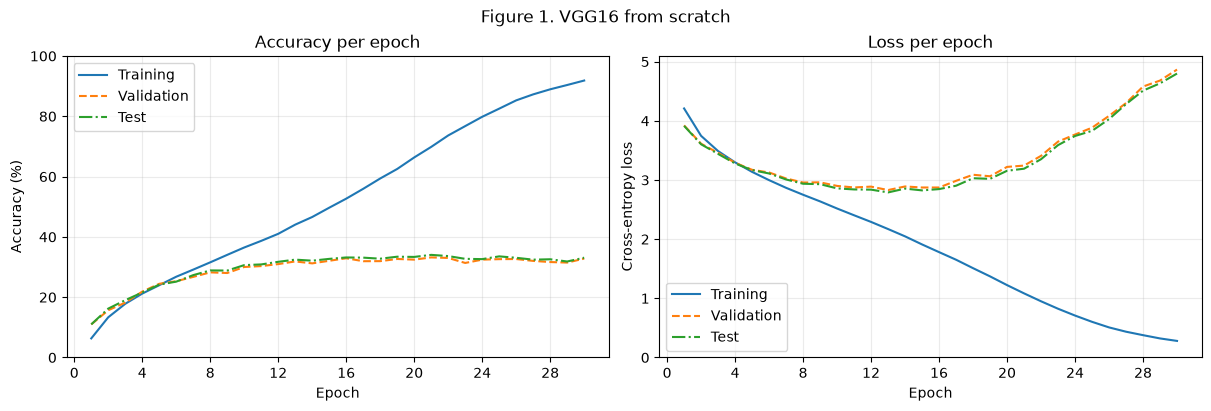

### Results for VGG16 from scratch

I obtained final validation accuracy of 32.80% and final test accuracy of 33.10%. The final test loss was 4.7990.

| Epoch | Training accuracy | Validation accuracy | Test accuracy | Training loss | Validation loss | Test loss |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 6.33% | 10.98% | 10.99% | 4.2091 | 3.9228 | 3.9144 |
| 15 | 49.68% | 32.08% | 32.71% | 1.9108 | 2.8732 | 2.8244 |
| 30 | 91.86% | 32.80% | 33.10% | 0.2802 | 4.8663 | 4.7990 |

The final training minus validation accuracy gap was +59.06 percentage points. I consider this gap together with the loss curves when assessing overfitting.

In [10]:
plot_model("vgg16_scratch")
display(Markdown(model_results_text("vgg16_scratch")))


## Exercise 2 Transfer learning

### Pretrained VGG16 and fine tuning

I use the same VGG16 architecture with ImageNet initialization and a new
100-class classification head. I fine-tune every layer from the first epoch.
The input size, preprocessing, optimizer and training budget remain the same
as in Exercise 1, so the backbone initialization is the difference between the runs.

Lecture 5 explains that pretrained features such as edges, textures and shapes
can reduce the learning needed for a new task. I assess whether this helps on
CIFAR-100 using final accuracy, the learning curves and time to the common target.


In [11]:
run_model("vgg16_transfer", lambda: build_vgg(pretrained=True))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cifar100_classifier (Dense)     │ (None, 100)            │        51,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,765,988 (56.33 MB)

 Trainable params: 14,765,988 (56.33 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
704/704 - 162s - 230ms/step - accuracy: 0.0875 - loss: 4.5592 - val_accuracy: 0.1890 - val_loss: 3.6930 - test_loss: 3.6842 - test_accuracy: 0.1895
Epoch 2/30
704/704 - 137s - 194ms/step - accuracy: 0.2654 - loss: 3.2467 - val_accuracy: 0.3290 - val_loss: 2.8982 - test_loss: 2.9095 - test_accuracy: 0.3265
Epoch 3/30
704/704 - 131s - 186ms/step - accuracy: 0.4033 - loss: 2.4751 - val_accuracy: 0.4064 - val_loss: 2.3926 - test_loss: 2.3950 - test_accuracy: 0.4121
Epoch 4/30
704/704 - 128s - 182ms/step - accuracy: 0.4963 - loss: 1.9767 - val_accuracy: 0.4648 - val_loss: 2.1641 - test_loss: 2.1568 - test_accuracy: 0.4605
Epoch 5/30
704/704 - 125s - 178ms/step - accuracy: 0.5662 - loss: 1.6537 - val_accuracy: 0.4930 - val_loss: 2.0357 - test_loss: 2.0282 - test_accuracy: 0.4940
Epoch 6/30
704/704 - 128s - 182ms/step - accuracy: 0.6253 - loss: 1.3959 - val_accuracy: 0.5054 - val_loss: 1.9801 - test_loss: 1.9769 - test_accuracy: 0.5109
Epoch 7/30
704/704 - 126s - 179ms/step - accur

### Accuracy and loss

I present training, validation and test accuracy on the left and the corresponding
losses on the right, using the same axes and line styles as in Exercise 1.


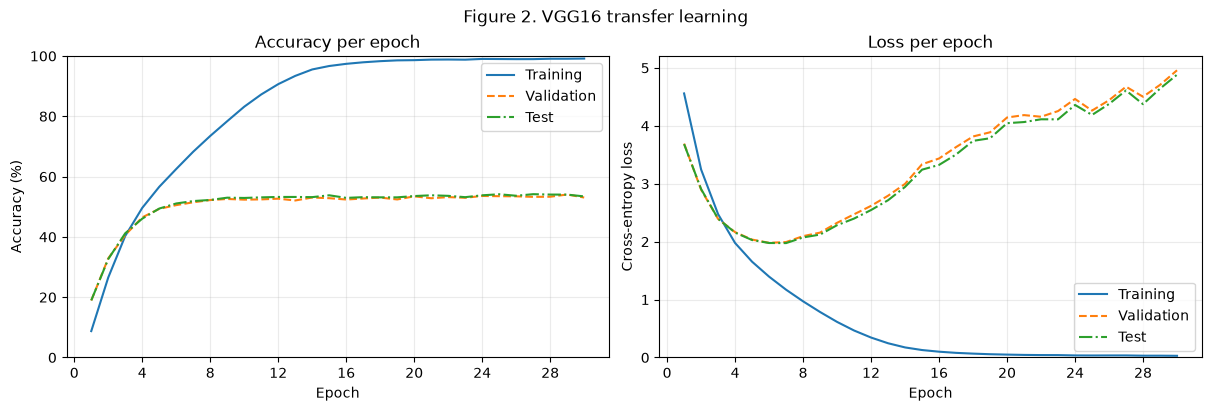

### Results for VGG16 transfer learning

I obtained final validation accuracy of 53.06% and final test accuracy of 53.43%. The final test loss was 4.8828.

| Epoch | Training accuracy | Validation accuracy | Test accuracy | Training loss | Validation loss | Test loss |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 8.75% | 18.90% | 18.95% | 4.5592 | 3.6930 | 3.6842 |
| 15 | 96.68% | 52.84% | 53.80% | 0.1287 | 3.3367 | 3.2430 |
| 30 | 99.15% | 53.06% | 53.43% | 0.0292 | 4.9590 | 4.8828 |

The final training minus validation accuracy gap was +46.09 percentage points. I consider this gap together with the loss curves when assessing overfitting.

In [12]:
plot_model("vgg16_transfer")
display(Markdown(model_results_text("vgg16_transfer")))


## Exercise 3 Vision Transformer

### Architecture and justification

I implement a ViT without pretrained weights. Following Lectures 7 and 9, I
represent the image as patch tokens with learned positional embeddings and use
self-attention to combine information across patches.

| Component | Choice | Purpose |
|---|---|---|
| Patch embedding | 8 × 8 patches projected to 192 features, followed by LayerNorm | Represent a 32 × 32 image with 16 tokens |
| Positional embeddings | 16 learned embeddings | Retain patch locations |
| Encoder depth | 6 blocks | Learn several stages of patch relationships |
| Self-attention | 6 heads, 32 features per head | Learn different relationships between patches |
| Feed-forward layers | Dense 768 with GELU, dropout, Dense 192, dropout | Transform each token's features |
| Block structure | Pre-layer normalization and two residual additions | Support stable training and gradient flow |
| Dropout | 0.1 | Reduce overfitting |
| Classification | Final LayerNorm, mean pooling and 100-class softmax | Aggregate the tokens for classification |

The patch projection uses a convolution whose kernel and stride equal the patch
size. I normalize the projections before adding positions to balance their initial
scales. Mean pooling combines all 16 tokens without a separate classification token.
I choose this compact architecture to limit attention cost. Smaller patches would
produce more tokens and increase attention computation. Unlike convolution,
attention does not impose the same local spatial structure. I consider these
differences and the parameter counts when comparing the models.


In [13]:
class PatchPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, image_size, patch_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.image_size, self.patch_size, self.embed_dim = image_size, patch_size, embed_dim
        self.num_patches = (image_size // patch_size) ** 2
        self.projection = tf.keras.layers.Conv2D(
            embed_dim, kernel_size=patch_size, strides=patch_size, padding="valid")
        self.token_norm = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.position = tf.keras.layers.Embedding(self.num_patches, embed_dim)

    def call(self, images):
        projected = self.projection(images)
        tokens = tf.reshape(projected, (-1, self.num_patches, self.embed_dim))
        return self.token_norm(tokens) + self.position(tf.range(self.num_patches))

    def get_config(self):
        return {**super().get_config(), "image_size": self.image_size,
                "patch_size": self.patch_size, "embed_dim": self.embed_dim}

def build_vit():
    inputs = tf.keras.Input((IMAGE_SIZE, IMAGE_SIZE, 3))
    tokens = PatchPositionEmbedding(IMAGE_SIZE, PATCH_SIZE, EMBED_DIM,
                                     name="patch_and_position")(inputs)
    tokens = tf.keras.layers.Dropout(DROPOUT)(tokens)
    for block in range(NUM_BLOCKS):
        normalized = tf.keras.layers.LayerNormalization(epsilon=1e-6)(tokens)
        attended = tf.keras.layers.MultiHeadAttention(
            num_heads=NUM_HEADS, key_dim=EMBED_DIM // NUM_HEADS,
            dropout=DROPOUT, name=f"attention_{block+1}")(normalized, normalized)
        tokens = tf.keras.layers.Add()([tokens, attended])
        normalized = tf.keras.layers.LayerNormalization(epsilon=1e-6)(tokens)
        transformed = tf.keras.layers.Dense(MLP_DIM, activation="gelu")(normalized)
        transformed = tf.keras.layers.Dropout(DROPOUT)(transformed)
        transformed = tf.keras.layers.Dense(EMBED_DIM)(transformed)
        transformed = tf.keras.layers.Dropout(DROPOUT)(transformed)
        tokens = tf.keras.layers.Add()([tokens, transformed])
    tokens = tf.keras.layers.LayerNormalization(epsilon=1e-6)(tokens)
    pooled = tf.keras.layers.GlobalAveragePooling1D()(tokens)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(pooled)
    return tf.keras.Model(inputs, outputs, name="vit_scratch")


In [14]:
run_model("vit_scratch", build_vit)


Model: "vit_scratch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_and_position  │ (None, 16, 192)   │     40,512 │ input_layer[0][0] │
│ (PatchPositionEmbe… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16, 192)   │          0 │ patch_and_positi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 192)   │        384 │ dropout[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_1         │ (None, 16, 192)   │    148,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 192)   │          0 │ dropout[0][0],    │
│                     │                   │            │ attention_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 192)   │        384 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16, 768)   │    148,224 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16, 768)   │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16, 192)   │    147,648 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 16, 192)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 192)   │          0 │ add[0][0],        │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 192)   │        384 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_2         │ (None, 16, 192)   │    148,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 16, 192)   │          0 │ add_1[0][0],      │
│                     │                   │            │ attention_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 192)   │        384 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16, 768)   │    148,224 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 16, 768)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 16, 192)   │    147,648 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,729,380 (10.41 MB)

 Trainable params: 2,729,380 (10.41 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


W0000 00:00:1794879310.988442    1580 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794879333.852421    1580 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794879450.622422    1583 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1794879450.695225    1583 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced


704/704 - 196s - 279ms/step - accuracy: 0.0433 - loss: 4.4147 - val_accuracy: 0.0674 - val_loss: 4.2137 - test_loss: 4.2017 - test_accuracy: 0.0716
Epoch 2/30


W0000 00:00:1794879466.132675    1581 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced


704/704 - 123s - 174ms/step - accuracy: 0.0748 - loss: 4.1512 - val_accuracy: 0.0852 - val_loss: 4.0937 - test_loss: 4.0731 - test_accuracy: 0.0918
Epoch 3/30
704/704 - 115s - 163ms/step - accuracy: 0.0907 - loss: 4.0430 - val_accuracy: 0.0992 - val_loss: 4.0111 - test_loss: 3.9893 - test_accuracy: 0.1023
Epoch 4/30
704/704 - 114s - 163ms/step - accuracy: 0.1019 - loss: 3.9666 - val_accuracy: 0.1034 - val_loss: 3.9501 - test_loss: 3.9238 - test_accuracy: 0.1130
Epoch 5/30
704/704 - 114s - 162ms/step - accuracy: 0.1142 - loss: 3.9039 - val_accuracy: 0.1110 - val_loss: 3.9038 - test_loss: 3.8792 - test_accuracy: 0.1159
Epoch 6/30
704/704 - 124s - 176ms/step - accuracy: 0.1204 - loss: 3.8489 - val_accuracy: 0.1194 - val_loss: 3.8588 - test_loss: 3.8328 - test_accuracy: 0.1222
Epoch 7/30
704/704 - 124s - 176ms/step - accuracy: 0.1283 - loss: 3.8007 - val_accuracy: 0.1240 - val_loss: 3.8188 - test_loss: 3.7914 - test_accuracy: 0.1300
Epoch 8/30
704/704 - 122s - 173ms/step - accuracy: 0.1352

### Accuracy and loss

I present training, validation and test accuracy on the left and the corresponding
losses on the right. I compare the final validation accuracy with VGG16 from Exercise 1.


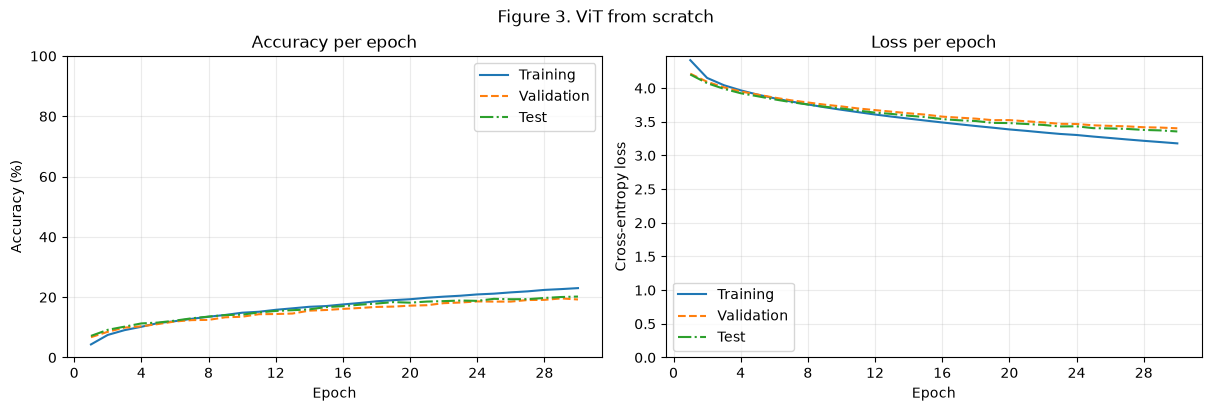

### Results for ViT from scratch

I obtained final validation accuracy of 19.24% and final test accuracy of 20.21%. The final test loss was 3.3561.

| Epoch | Training accuracy | Validation accuracy | Test accuracy | Training loss | Validation loss | Test loss |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 4.33% | 6.74% | 7.16% | 4.4147 | 4.2137 | 4.2017 |
| 15 | 17.06% | 15.76% | 16.72% | 3.5181 | 3.6061 | 3.5698 |
| 30 | 23.01% | 19.24% | 20.21% | 3.1791 | 3.4029 | 3.3561 |

The final training minus validation accuracy gap was +3.77 percentage points. I consider this gap together with the loss curves when assessing overfitting.

In [15]:
plot_model("vit_scratch")
display(Markdown(model_results_text("vit_scratch")))


## Comparison of the three models

The first overall plot compares test accuracy per epoch for all three models.
The second compares test cross-entropy loss per epoch. I assess transfer learning
by comparing the two VGG16 runs and compare the scratch ViT with the scratch VGG16.


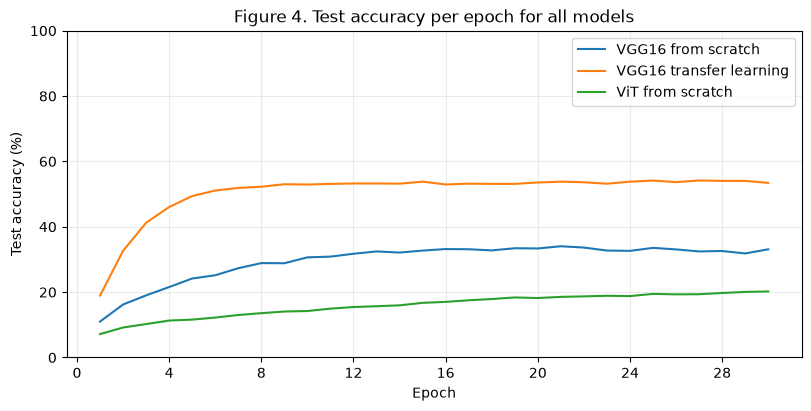

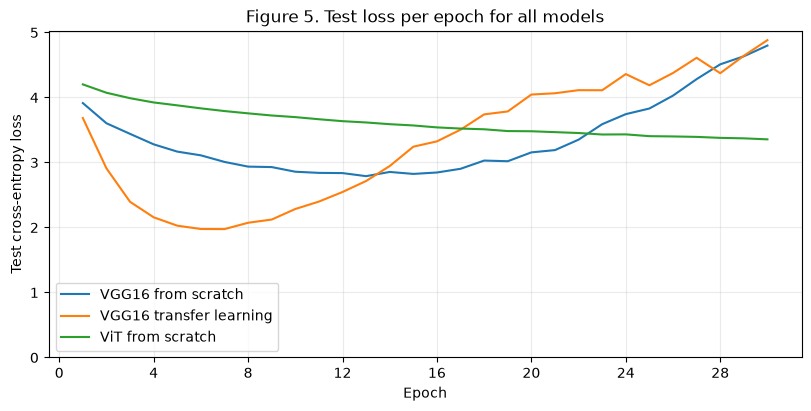

In [16]:
plot_test_comparisons()


### Excersie 2
epochs that has the best accuransy the VGG16 from scrats.
As we can see from the results, by using the pre-trained model, we achieved much higher accuracy and lower loss per epoch compared to the VGG16 model trained with randomly initialized weights. We can also observe that the best result in the case of transfer learning was achieved at epoch 6, which is much faster than the 13 epochs required for the VGG16 model trained from scratch to achieve its best accuracy.

### Excersie 3
If we compare the ViT model trained from scratch with the VGG16 models, we can easily identify that both VGG16 techniques achieve much better results in the earlier epochs. However, with a closer look, we can also observe that both VGG16 techniques have achieved their best results and are starting to overfit, while the ViT model is still improving its performance. This suggests that Vision Transformers require more data and training to achieve good results compared to VGG16 models. The training and testing speeds were very similar across all models.